In [1]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


## Get Jack's numbers

In [2]:
jackDF = pd.read_csv('../../jacksFiles/B2F_page2_table.csv',index_col=0)
jackDF = jackDF.rename(columns={'mS_GeV':'ms', 'm1_GeV':'m1', 'Delta_m10':'dm','sigma_fb' : 'xsec_fb'})
jackDF = jackDF.drop(columns=['beta_chi1_scalar_rest_frame','N_Run2_plus_3'])

In [3]:
jackDF

,ms,m1,dm,xsec_fb,N_Run2
id,,,,,
100004,450,215.5,60,32.78,1.57
100008,450,204.1,60,74.47,1.53
100006,450,212.4,60,46.63,1.29
100016,600,283.9,60,8.33,1.15
100009,450,204.1,100,71.43,0.98
100007,450,212.4,100,44.91,0.92
100018,600,272.9,60,14.49,0.90
100014,600,288.1,60,5.81,0.76
100005,450,215.5,100,31.51,0.65


### Get B2TF recast data

In [5]:
b2tf_DF = pd.read_csv('../b2tf_effs_13TeV.csv')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
b2tf_DF['xsec_fb'] = (b2tf_DF['xsec_pb']*1e3)
b2tf_DF['N_Run2'] = b2tf_DF['eff']*b2tf_DF['xsec_fb']*139.0
b2tf_DF['N_Run2_err'] = b2tf_DF['efferror']*b2tf_DF['xsec_fb']*139.0
b2tf_DF = b2tf_DF[b2tf_DF['dm'] < 250].copy()

In [6]:
b2tf_DF['ms'].unique(),b2tf_DF['ctau'].unique()

(array([ 300.,  700.,  900., 1100.,  500.]), array([10., 20., 49., 50.]))

In [8]:
b2tf_DF = b2tf_DF.sort_values(by=['N_Run2','eff','ms'],ascending=[False,False,True])
b2tf_DF[['ms','m1','dm','ctau','eff','N_Run2']].head(10)

,ms,m1,dm,ctau,eff,N_Run2
219,500.0,195.0,15.0,10.0,0.001189,4.571396
222,500.0,195.0,50.0,10.0,0.000835,4.190792
223,500.0,195.0,50.0,20.0,0.000841,4.185331
30,300.0,120.0,15.0,20.0,0.000392,4.039437
220,500.0,195.0,15.0,20.0,0.001031,3.973959
208,500.0,220.0,15.0,20.0,0.001388,3.860569
207,500.0,220.0,15.0,10.0,0.001316,3.638358
210,500.0,220.0,50.0,10.0,0.000999,3.583597
211,500.0,220.0,50.0,20.0,0.000887,3.161752
224,500.0,195.0,50.0,50.0,0.000614,3.044649


### Add ratio to Jack's Numbers

In [6]:
# Round the keys before matching: dm = m1 - m0 has floating-point noise,
# and Jack's masses are given to 1 decimal place
keys = ['ms', 'm1', 'dm']
jack_keyed = jackDF[keys + ['xsec_fb', 'N_Run2']].copy()
jack_keyed[keys] = jack_keyed[keys].round(1)

b2tf_keyed = b2tf_DF.copy()
b2tf_keyed[keys] = b2tf_keyed[keys].round(1)

merged = b2tf_keyed.merge(jack_keyed, on=keys, how='left',
                          suffixes=('', '_jack'), validate='many_to_one')

b2tf_DF['N_Run2_jack'] = merged['N_Run2_jack'].values
b2tf_DF['xsec_jack'] = merged['xsec_fb_jack'].values
b2tf_DF['N_Run2_ratio'] = b2tf_DF['N_Run2'] / b2tf_DF['N_Run2_jack']
b2tf_DF['N_Run2_ratio_err'] = b2tf_DF['N_Run2_err'] / b2tf_DF['N_Run2_jack']



In [7]:
b2tf_match = b2tf_DF[b2tf_DF['N_Run2_ratio'].notnull()]
b2tf_match = b2tf_match.sort_values(by=['N_Run2_jack'], ascending=False)
# b2tf_match[['ms', 'm1', 'dm', 'N_Run2', 'N_Run2_err', 'N_Run2_jack', 'N_Run2_ratio', 'N_Run2_ratio_err']]
b2tf_match[['ms', 'm1', 'dm', 'N_Run2', 'N_Run2_jack', 'N_Run2_ratio','filename']]

,ms,m1,dm,N_Run2,N_Run2_jack,N_Run2_ratio,filename


In [ ]:
effsDF = b2tf_DF.sort_values(by='eff',ascending=False).copy()
effsDF[['ms', 'm1', 'dm', 'ctau', 'eff', 'efferror', 'N_Run2']].head(10)


,ms,m1,dm,ctau,eff,efferror
142,1100.0,520.0,200.0,20.0,0.008288,0.000515
115,1100.0,540.0,15.0,20.0,0.008173,0.000517
134,1100.0,520.0,50.0,10.0,0.008168,0.000512
119,1100.0,540.0,50.0,20.0,0.008148,0.000515
131,1100.0,520.0,15.0,10.0,0.008081,0.000511
132,1100.0,520.0,15.0,20.0,0.007822,0.000501
125,1100.0,540.0,200.0,20.0,0.007764,0.000500
141,1100.0,520.0,200.0,10.0,0.007624,0.000496
124,1100.0,540.0,200.0,10.0,0.007554,0.000495
114,1100.0,540.0,15.0,10.0,0.007527,0.000494


In [29]:
nDF = b2tf_DF.sort_values(by='N_Run2',ascending=False).copy()
nDF[['ms', 'm1', 'dm', 'ctau','N_Run2','N_Run2_err']].head(10)


,ms,m1,dm,ctau,N_Run2,N_Run2_err
219,500.0,195.0,15.0,10.0,4.571396,0.820852
222,500.0,195.0,50.0,10.0,4.190792,0.893440
223,500.0,195.0,50.0,20.0,4.185331,0.892233
30,300.0,120.0,15.0,20.0,4.039437,1.346136
220,500.0,195.0,15.0,20.0,3.973959,0.764727
208,500.0,220.0,15.0,20.0,3.860569,0.643336
207,500.0,220.0,15.0,10.0,3.638358,0.623995
210,500.0,220.0,50.0,10.0,3.583597,0.702722
211,500.0,220.0,50.0,20.0,3.161752,0.659233
224,500.0,195.0,50.0,50.0,3.044649,0.761286


## Plot Effs

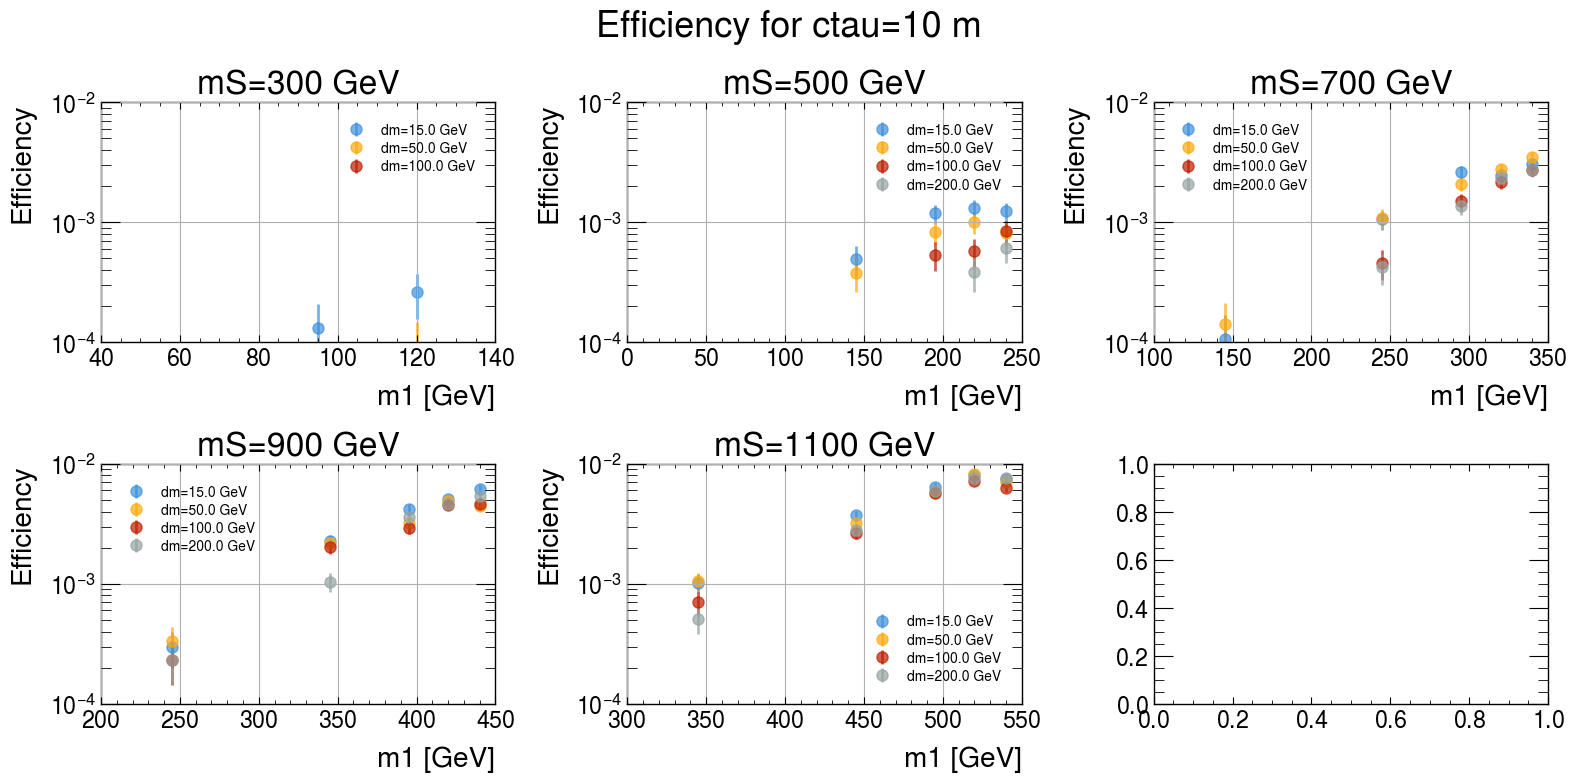

In [24]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 3
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
ctau = 10.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-4, 1e-2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()

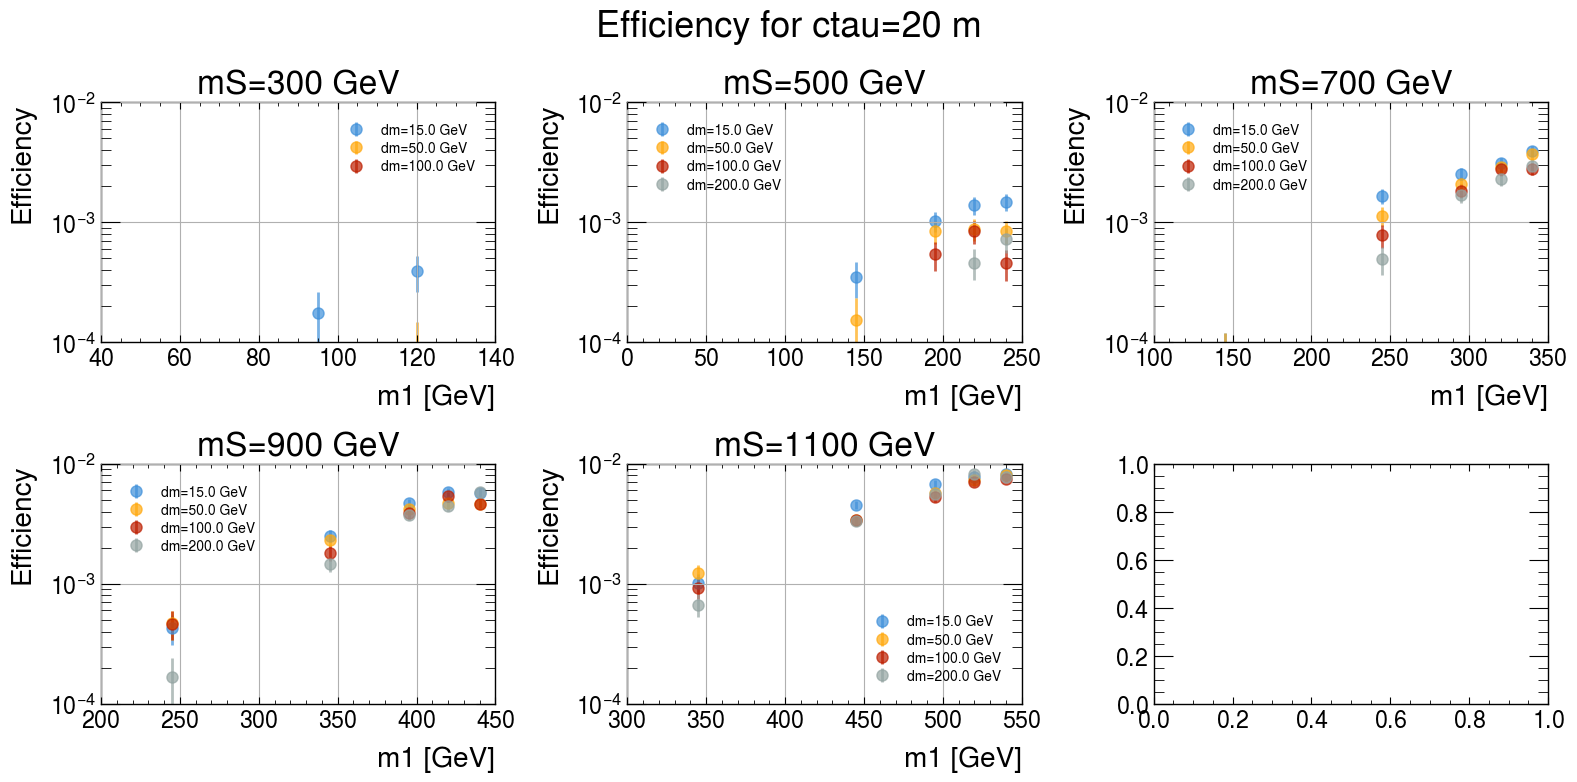

In [25]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 3
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
ctau = 20.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-4, 1e-2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()

/tmp/ipykernel_259817/3448382162.py:20: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axes[iax].set_yscale('log')


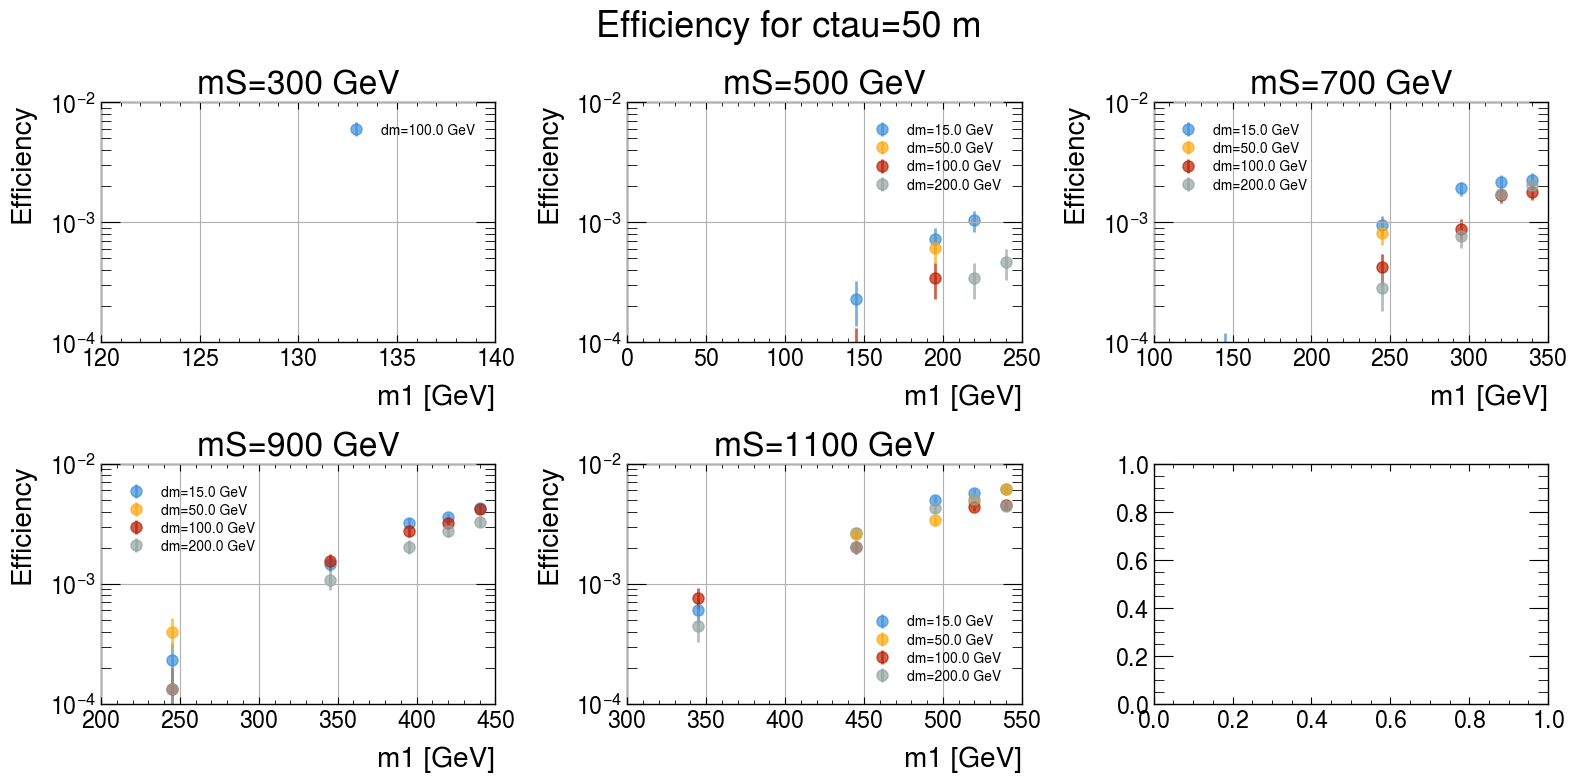

In [26]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 3
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
ctau = 50.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-4, 1e-2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()

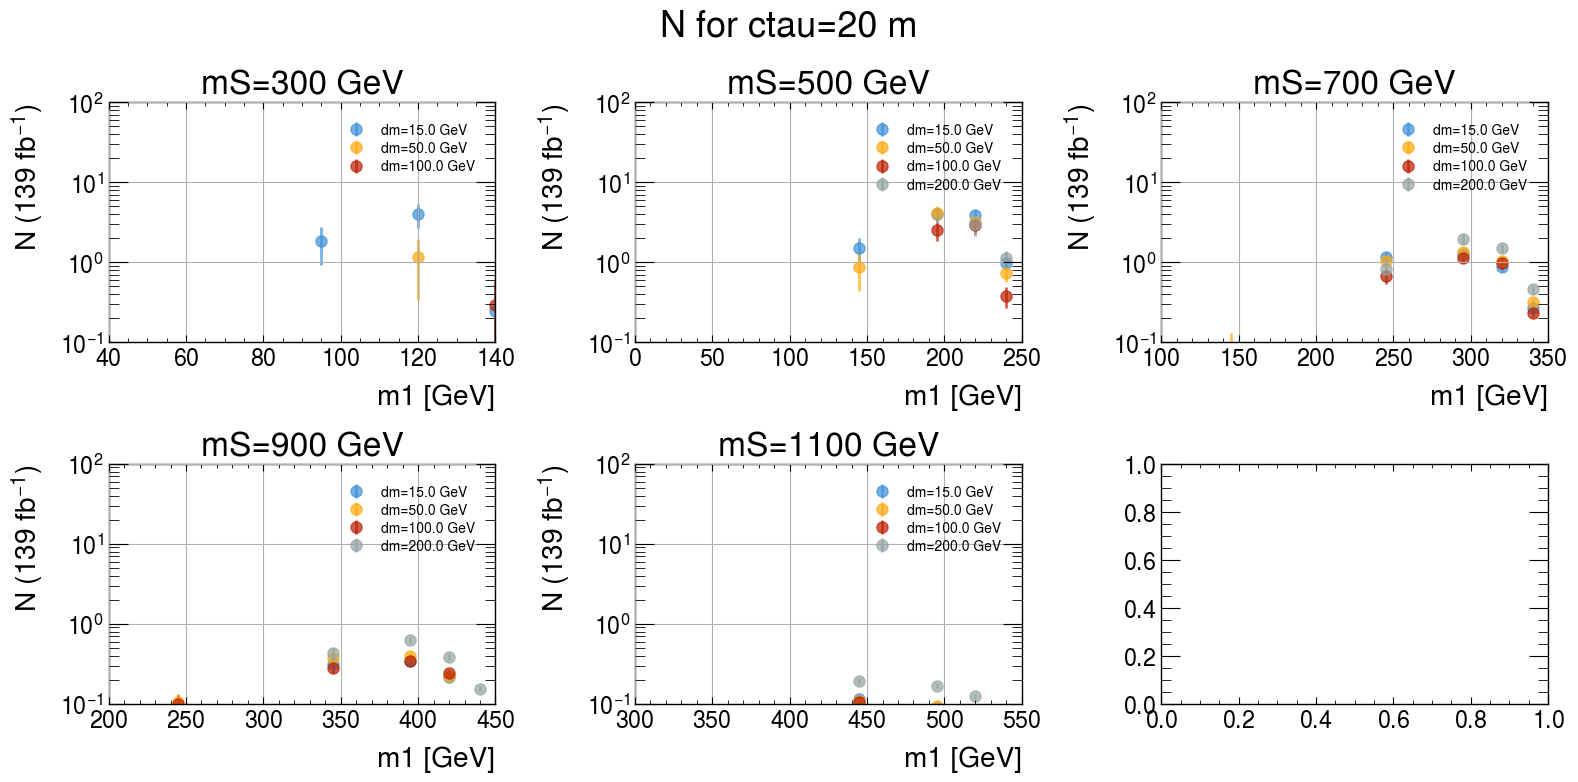

In [33]:
ncolumns = 3
mSValues = sorted(b2tf_DF['ms'].unique())
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = 20.0
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['N_Run2'], 
                            yerr=dfB['N_Run2_err'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        # alpha -= 0.2
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel(r'N (139 fb$^{-1}$)')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-1, 1e2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'N for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()